# 📈 Average and Moving Average Forecasting

A detailed, mathematical and visual introduction to two foundational time-series forecasting methods.

**Learning objectives**
- Understand the Average (Mean) Method and Simple Moving Average (SMA).
- Derive and calculate each method mathematically.
- Understand window size, smoothing, lag, and forecast horizon.
- Distinguish smoothing historical data from forecasting future values.
- Understand recursive multi-step forecasts and Weighted Moving Average (WMA).
- Evaluate forecasts and select a window without data leakage.

All datasets are synthetic and generated in this notebook.

## 1. Why start with averages?

Time series observations fluctuate over time. An average summarizes a collection of observations into a representative value.

- **Average Method:** Uses the mean of all observations in the training history. Every future forecast is the same.
- **Moving Average Method:** Uses only the most recent fixed number of observations. The window advances as new observations arrive.

These are useful baselines, but neither method explicitly models trend or seasonality.

## 2. Average Method (Mean Forecast)

### Intuition
Suppose demand over five weeks is `100, 120, 110, 130, 140`. The mean is 120 units. The Average Method forecasts 120 for every future week.

### Mathematical explanation

Let $y_1,\ldots,y_T$ be the training observations and $T$ the number of observations.

$$
\bar{y}=\frac{1}{T}\sum_{t=1}^{T}y_t
$$

For a forecast horizon $h=1,\ldots,H$:

$$
\hat{y}_{T+h}=\bar{y}
$$

The forecast is constant across the horizon. The method assumes the future level will be similar to the average historical level; it does not adjust for trend or seasonality.

Training observations: [100, 120, 110, 130, 140]
Sum: 600
Count: 5
Mean: 120.0
Next four forecasts: [120.0, 120.0, 120.0, 120.0]


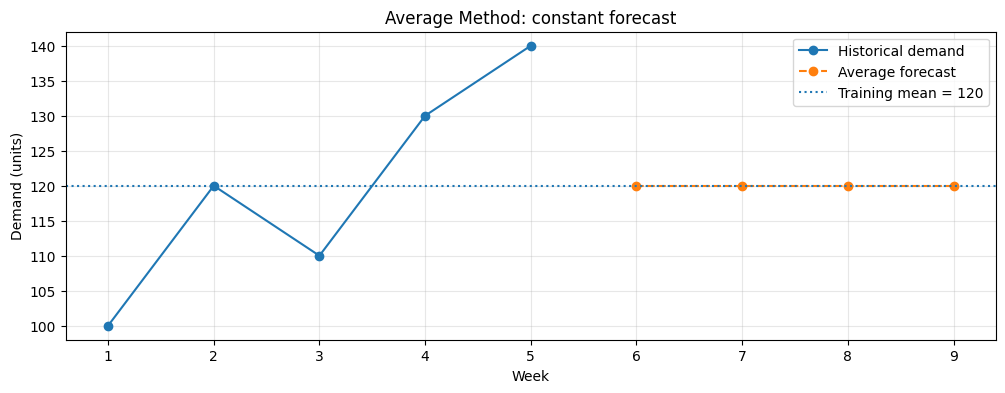

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

history = pd.Series([100, 120, 110, 130, 140], index=range(1, 6), name="Demand")
mean_value = history.mean()
horizon = 4
mean_forecast = pd.Series([mean_value] * horizon, index=range(6, 10))

print("Training observations:", history.tolist())
print("Sum:", history.sum())
print("Count:", len(history))
print("Mean:", mean_value)
print("Next four forecasts:", mean_forecast.tolist())

fig, ax = plt.subplots()
ax.plot(history.index, history, marker="o", label="Historical demand")
ax.plot(mean_forecast.index, mean_forecast, marker="o", linestyle="--", label="Average forecast")
ax.axhline(mean_value, linestyle=":", label=f"Training mean = {mean_value:.0f}")
ax.set(title="Average Method: constant forecast", xlabel="Week", ylabel="Demand (units)")
ax.legend()
plt.show()

### Worked calculation

| Week | Actual demand |
|---|---:|
| 1 | 100 |
| 2 | 120 |
| 3 | 110 |
| 4 | 130 |
| 5 | 140 |
| **Total** | **600** |

Mean = 600 / 5 = **120 units**.

Therefore, Week 6 = 120, Week 7 = 120, Week 8 = 120, and so on.

### Sensitivity to extreme values

Because every training observation contributes to the mean, an unusually high or low observation can change the forecast. The method may also respond slowly to a recent level shift because older values remain included.

Mean, ordinary history: 120.0
Mean, history with high final value: 152.0


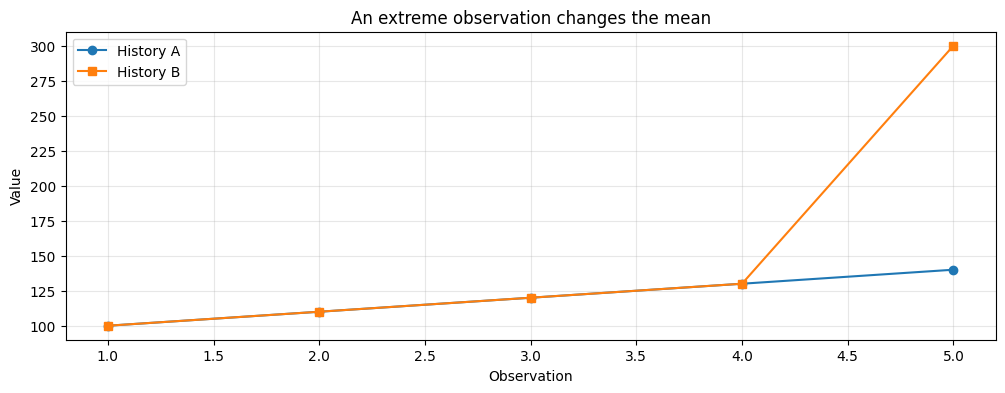

In [2]:
history_a = np.array([100, 110, 120, 130, 140])
history_b = np.array([100, 110, 120, 130, 300])
print("Mean, ordinary history:", history_a.mean())
print("Mean, history with high final value:", history_b.mean())

fig, ax = plt.subplots()
ax.plot(range(1, 6), history_a, marker="o", label="History A")
ax.plot(range(1, 6), history_b, marker="s", label="History B")
ax.set(title="An extreme observation changes the mean", xlabel="Observation", ylabel="Value")
ax.legend()
plt.show()

### Advantages
- Easy to understand and implement.
- No parameter tuning is required.
- Useful as a benchmark for stable-level series.
- Uses all observations in the training history.

### Limitations
- Produces a constant forecast.
- Does not explicitly capture trend or seasonality.
- Can be influenced by extreme values.
- May react slowly to changes in the recent level.

### Potential applications
- Baseline forecasting for relatively stable demand.
- Estimating a typical level.
- Benchmarking more advanced models.

## 3. Simple Moving Average (SMA)

### Intuition
A moving average calculates the mean of a fixed number of recent observations. For a window of 3, it first averages observations 1–3, then 2–4, then 3–5. The window moves forward one observation at a time.

### Mathematical explanation

Let $y_t$ be the observation at time $t$, and let $k$ be the window size.

$$
\text{MA}_t=\frac{1}{k}\sum_{i=0}^{k-1}y_{t-i}
$$

Expanded:

$$
\text{MA}_t=\frac{y_t+y_{t-1}+\cdots+y_{t-k+1}}{k}
$$

For a one-step-ahead forecast made after observing time $T$:

$$
\hat{y}_{T+1}=\frac{y_T+y_{T-1}+\cdots+y_{T-k+1}}{k}
$$

In words: add the latest $k$ actual observations and divide by $k$.

In [3]:
values = pd.Series([100, 120, 110, 130, 140], index=range(1, 6), name="Demand")
k = 3
rolling_ma = values.rolling(window=k).mean()
next_forecast = values.tail(k).mean()

display(pd.DataFrame({"Actual": values, f"Trailing MA (k={k})": rolling_ma}))
print("Latest observations:", values.tail(k).tolist())
print(f"Next-period forecast: {next_forecast:.2f}")

,Actual,Trailing MA (k=3)
1,100,NaN
2,120,NaN
3,110,110.000000
4,130,120.000000
5,140,126.666667


Latest observations: [110, 130, 140]
Next-period forecast: 126.67


### Worked example: window size = 3

Demand: `100, 120, 110, 130, 140`

- Week 3: (100 + 120 + 110) / 3 = 110
- Week 4: (120 + 110 + 130) / 3 = 120
- Week 5: (110 + 130 + 140) / 3 = 126.67

After observing Week 5, the forecast for Week 6 is **126.67 units**, calculated from the latest three actual observations.

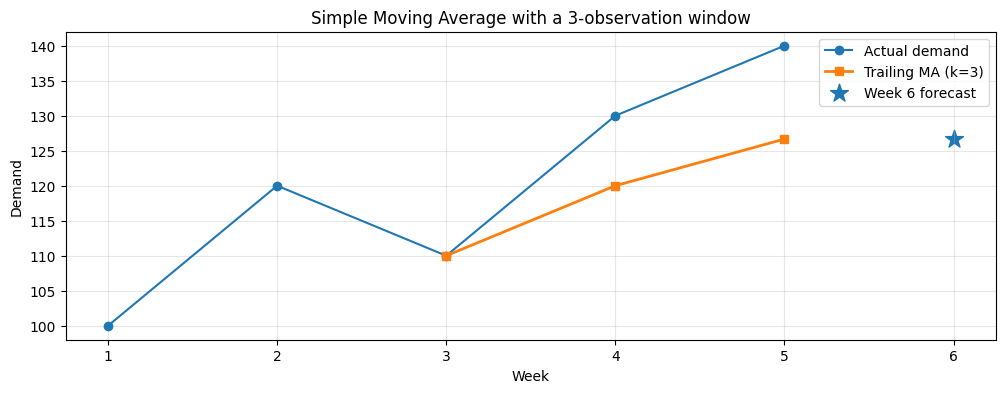

In [4]:
fig, ax = plt.subplots()
ax.plot(values.index, values, marker="o", label="Actual demand")
ax.plot(rolling_ma.index, rolling_ma, marker="s", linewidth=2, label=f"Trailing MA (k={k})")
ax.scatter([6], [next_forecast], marker="*", s=180, label="Week 6 forecast")
ax.set(title="Simple Moving Average with a 3-observation window", xlabel="Week", ylabel="Demand")
ax.legend()
plt.show()

### Why is it called a moving average?

For values `10, 20, 30, 40, 50` and \(k=3\):

| Window | Calculation | Average |
|---|---|---:|
| 1–3 | (10 + 20 + 30) / 3 | 20 |
| 2–4 | (20 + 30 + 40) / 3 | 30 |
| 3–5 | (30 + 40 + 50) / 3 | 40 |

Each time a new observation arrives, the oldest value leaves the window and the newest value enters it.

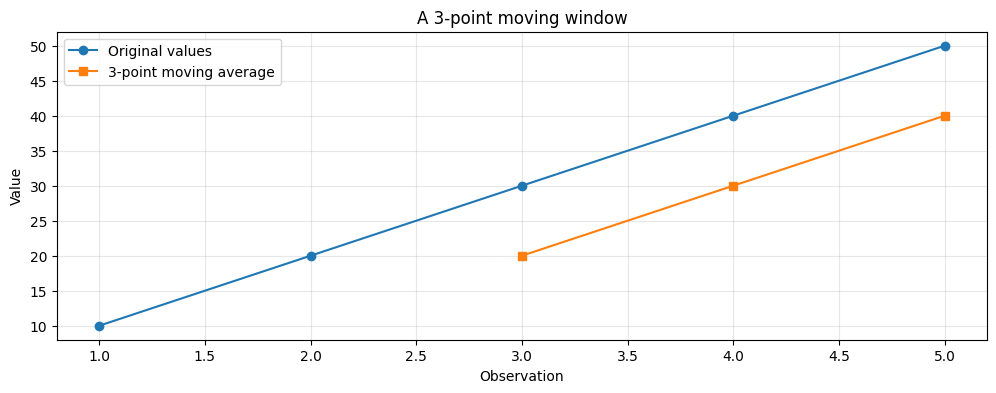

In [5]:
demo = pd.Series([10, 20, 30, 40, 50])
demo_ma = demo.rolling(3).mean()
fig, ax = plt.subplots()
ax.plot(range(1, 6), demo, marker="o", label="Original values")
ax.plot(range(1, 6), demo_ma, marker="s", label="3-point moving average")
ax.set(title="A 3-point moving window", xlabel="Observation", ylabel="Value")
ax.legend()
plt.show()

## 4. Choosing the window size

The window \(k\) controls how much recent history contributes.

**Small window**
- Reacts faster to recent changes.
- Retains more short-term fluctuation.
- Produces less smoothing.

**Large window**
- Produces a smoother line.
- Reduces short-term noise.
- Reacts more slowly to a change because older values remain in the window.

Examples are context-dependent: 7 observations may represent a week for daily data; 4 observations may represent roughly a month for weekly data; 12 observations may represent a year for monthly data. These are examples, not universal rules.

There is no universally best window. Select it using a validation period that reflects the real forecast horizon and business objective.

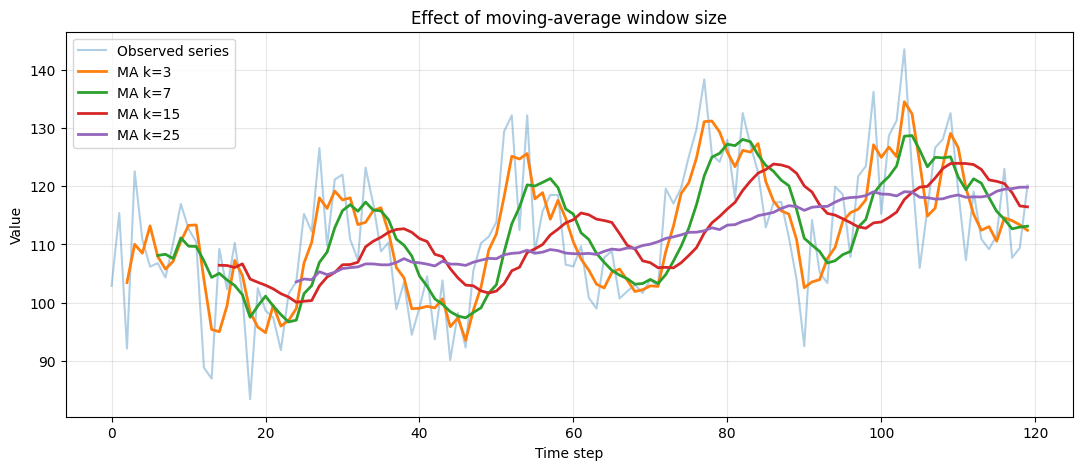

In [6]:
rng = np.random.default_rng(21)
n = 120
x = np.arange(n)
underlying = 100 + 0.2*x + 12*np.sin(2*np.pi*x/24)
noisy = pd.Series(underlying + rng.normal(0, 8, n))
windows = [3, 7, 15, 25]

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(noisy, alpha=0.35, label="Observed series")
for w in windows:
    ax.plot(noisy.rolling(w).mean(), linewidth=2, label=f"MA k={w}")
ax.set(title="Effect of moving-average window size", xlabel="Time step", ylabel="Value")
ax.legend()
plt.show()

## 5. Smoothing vs forecasting: trailing and centered averages

A moving average can be used for two related but different purposes.

- **Smoothing:** Summarizes historical values to make the underlying pattern easier to see.
- **Forecasting:** Uses only values available at the forecast origin to predict a future value.

A **trailing** moving average at time \(t\) uses the current and previous observations. A **centered** moving average is aligned around the center of its window and can use observations both before and after that timestamp.

Centered averages can be useful for retrospective analysis, but future observations are not available when making a real-time forecast. For forecasting features, use trailing windows and avoid look-ahead bias.

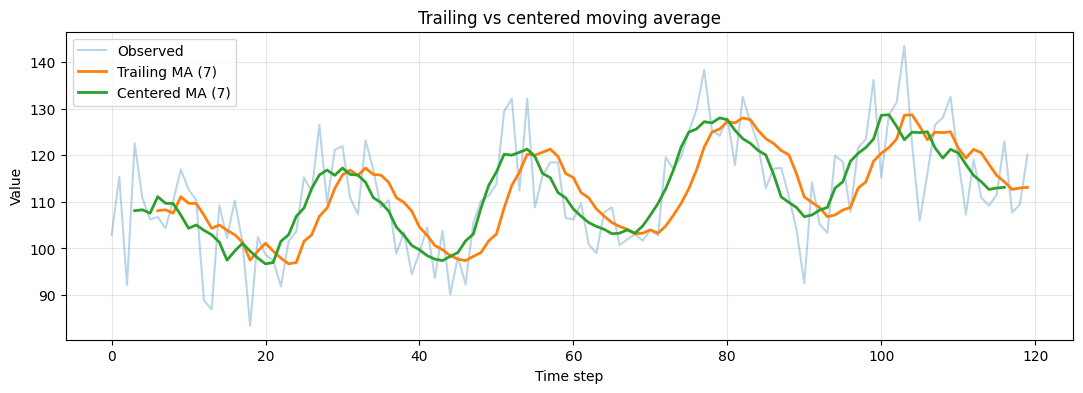

In [7]:
trailing = noisy.rolling(window=7).mean()
centered = noisy.rolling(window=7, center=True).mean()
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(noisy, alpha=0.3, label="Observed")
ax.plot(trailing, linewidth=2, label="Trailing MA (7)")
ax.plot(centered, linewidth=2, label="Centered MA (7)")
ax.set(title="Trailing vs centered moving average", xlabel="Time step", ylabel="Value")
ax.legend()
plt.show()

## 6. Multi-step moving-average forecasts

For a one-step forecast, average the latest \(k\) actual observations.

For multiple steps, future actual values are unknown. A common approach is **recursive forecasting**:

1. Calculate the first forecast from the latest \(k\) actual observations.
2. Append that forecast to the history.
3. Calculate the next forecast from the latest \(k\) values, which may now include a forecast.
4. Repeat until the required horizon is reached.

Later forecasts therefore depend partly on earlier predictions. The series may become increasingly smooth, and the forecast cannot anticipate future changes that have not yet been observed.

In [8]:
def moving_average_forecast(history, window, horizon):
    if window <= 0:
        raise ValueError("window must be positive")
    if len(history) < window:
        raise ValueError("history must contain at least window observations")
    extended = list(history)
    forecasts = []
    for _ in range(horizon):
        prediction = float(np.mean(extended[-window:]))
        forecasts.append(prediction)
        extended.append(prediction)
    return np.array(forecasts)

example_history = [100, 120, 110, 130, 140]
recursive = moving_average_forecast(example_history, window=3, horizon=5)
display(pd.DataFrame({"Step ahead": range(1, 6), "Forecast": recursive}))

,Step ahead,Forecast
0,1,126.666667
1,2,132.222222
2,3,132.962963
3,4,130.617284
4,5,131.934156


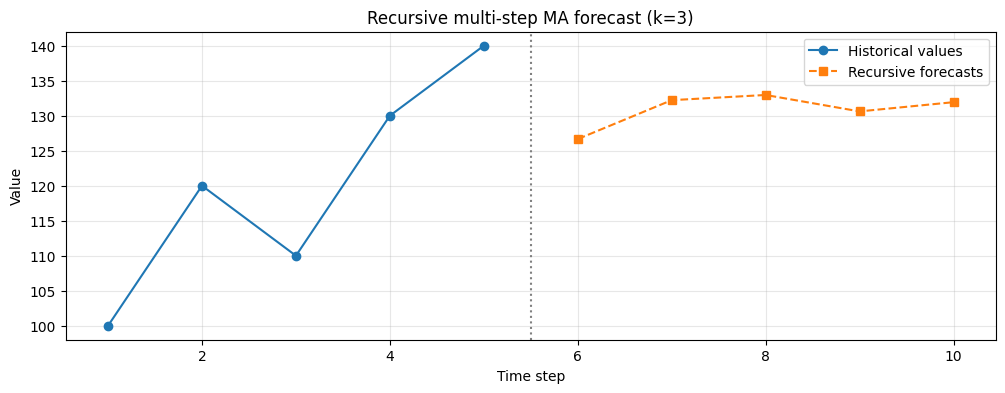

In [9]:
fig, ax = plt.subplots()
ax.plot(range(1, 6), example_history, marker="o", label="Historical values")
ax.plot(range(6, 11), recursive, marker="s", linestyle="--", label="Recursive forecasts")
ax.axvline(5.5, linestyle=":", color="gray")
ax.set(title="Recursive multi-step MA forecast (k=3)", xlabel="Time step", ylabel="Value")
ax.legend()
plt.show()

## 7. Weighted Moving Average (WMA)

A Simple Moving Average gives every observation in the window equal weight. A **Weighted Moving Average** assigns different weights.

\[
WMA_T=\sum_{i=1}^{k}w_i y_i
\]

where the weights satisfy:

\[
\sum_{i=1}^{k}w_i=1
\]

Example: values = 110, 130, 140 and weights = 0.2, 0.3, 0.5.

WMA = (0.2 × 110) + (0.3 × 130) + (0.5 × 140) = **132**.

The latest observation has the greatest influence because it receives the largest weight. Weights may be chosen based on domain knowledge or validation performance; do not tune them on the final test set.

SMA: 126.66666666666666
WMA: 131.0
Weight total: 1.0


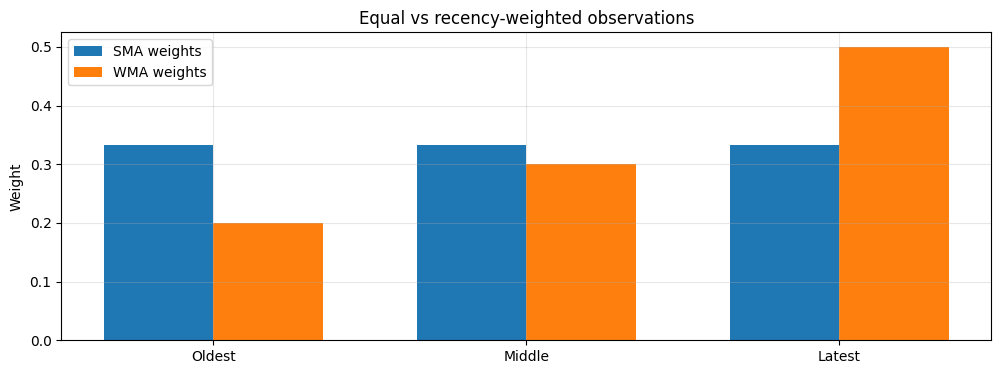

In [10]:
observations = np.array([110, 130, 140])
equal_weights = np.array([1/3, 1/3, 1/3])
recent_weights = np.array([0.2, 0.3, 0.5])

print("SMA:", np.sum(observations * equal_weights))
print("WMA:", np.sum(observations * recent_weights))
print("Weight total:", recent_weights.sum())

fig, ax = plt.subplots()
pos = np.arange(3)
width = 0.35
ax.bar(pos-width/2, equal_weights, width, label="SMA weights")
ax.bar(pos+width/2, recent_weights, width, label="WMA weights")
ax.set_xticks(pos, ["Oldest", "Middle", "Latest"])
ax.set(title="Equal vs recency-weighted observations", ylabel="Weight")
ax.legend()
plt.show()

### SMA vs WMA

| Simple Moving Average | Weighted Moving Average |
|---|---|
| Equal weights | Different weights |
| Simple to calculate | Requires weight selection |
| All observations in the window contribute equally | Some observations have more influence |
| Basic smoothing / baseline | Can emphasize recent observations |

## 8. Average vs Moving Average

| Aspect | Average Method | Moving Average |
|---|---|---|
| Data used | All training observations | Most recent \(k\) observations |
| Forecast | Constant across horizon | Updated from latest available values |
| Parameter | None | Window size \(k\) |
| Recent changes | May react slowly | Small window reacts faster |
| Trend / seasonality | Not explicitly modelled | Not explicitly modelled |
| Use | Stable-level baseline | Smoothing and short-term baseline |

A moving average is not automatically a trend or seasonal model. It summarizes recent observations; it does not explicitly learn a trend or repeating seasonal structure.

## 9. Practical monthly demand example

Create synthetic monthly demand containing:
- An upward trend.
- A repeating annual seasonal pattern.
- Random noise.

We will use the first 60 months for training and the final 12 months for testing. The test data will not be used to calculate the training mean or initial moving-average window.

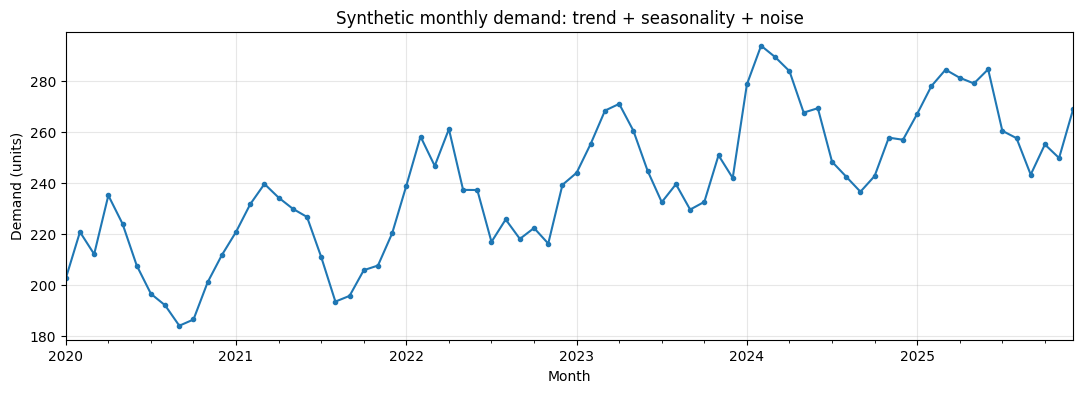

In [11]:
rng = np.random.default_rng(2026)
dates = pd.date_range("2020-01-01", periods=72, freq="MS")
t = np.arange(len(dates))
trend = 1.1*t
seasonality = 22*np.sin(2*np.pi*t/12) + 8*np.cos(2*np.pi*t/12)
noise = rng.normal(0, 7, len(t))
ts = pd.Series(200 + trend + seasonality + noise, index=dates, name="Demand")

fig, ax = plt.subplots(figsize=(13, 4))
ts.plot(ax=ax, marker=".", linewidth=1.5)
ax.set(title="Synthetic monthly demand: trend + seasonality + noise",
       xlabel="Month", ylabel="Demand (units)")
plt.show()

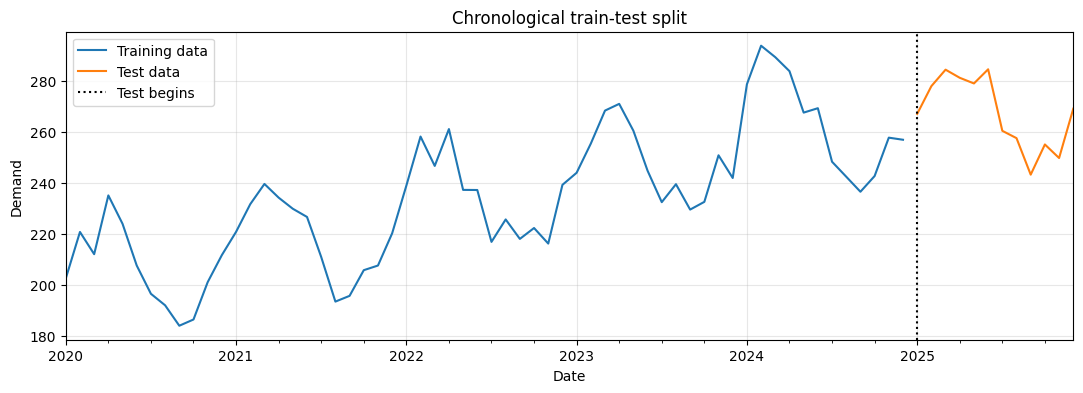

Training rows: 60 | Test rows: 12
Training: 2020-01-01 to 2024-12-01
Test: 2025-01-01 to 2025-12-01


In [12]:
train = ts.iloc[:-12]
test = ts.iloc[-12:]

fig, ax = plt.subplots(figsize=(13, 4))
train.plot(ax=ax, label="Training data")
test.plot(ax=ax, label="Test data")
ax.axvline(test.index[0], color="black", linestyle=":", label="Test begins")
ax.set(title="Chronological train-test split", xlabel="Date", ylabel="Demand")
ax.legend()
plt.show()

print("Training rows:", len(train), "| Test rows:", len(test))
print("Training:", train.index.min().date(), "to", train.index.max().date())
print("Test:", test.index.min().date(), "to", test.index.max().date())

### 9.1 Average Method forecast

Calculate the mean from training observations only. Repeat this value for all 12 test months.

In [13]:
mean_level = train.mean()
mean_test_forecast = pd.Series(mean_level, index=test.index, name="Average forecast")
print(f"Training mean forecast: {mean_level:.2f}")

Training mean forecast: 234.07


### 9.2 Moving Average forecast

Use a 3-month window. The first forecast averages the final three training observations. Later forecasts are recursive and may use previous predictions.

In [14]:
window = 3
ma_test_forecast = pd.Series(
    moving_average_forecast(train.to_list(), window, len(test)),
    index=test.index,
    name=f"Moving Average (k={window})"
)
display(ma_test_forecast.head())

2025-01-01    252.463303
2025-02-01    255.722134
2025-03-01    255.041517
2025-04-01    254.408985
2025-05-01    255.057546
Freq: MS, Name: Moving Average (k=3), dtype: float64

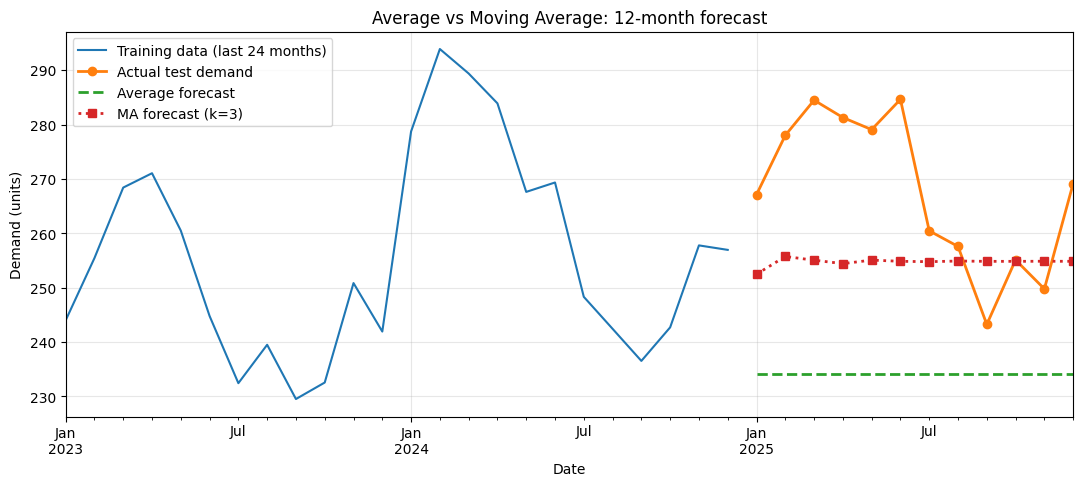

In [15]:
fig, ax = plt.subplots(figsize=(13, 5))
train.iloc[-24:].plot(ax=ax, label="Training data (last 24 months)")
test.plot(ax=ax, marker="o", linewidth=2, label="Actual test demand")
mean_test_forecast.plot(ax=ax, linestyle="--", linewidth=2, label="Average forecast")
ma_test_forecast.plot(ax=ax, linestyle=":", marker="s", linewidth=2, label=f"MA forecast (k={window})")
ax.set(title="Average vs Moving Average: 12-month forecast",
       xlabel="Date", ylabel="Demand (units)")
ax.legend()
plt.show()

## 10. Forecast evaluation

We will calculate four common metrics:

- **MAE:** Mean Absolute Error = average of |Actual − Forecast|.
- **RMSE:** Root Mean Squared Error = square root of average squared error.
- **MAPE:** Mean Absolute Percentage Error = average of (|Actual − Forecast| / |Actual|) × 100.
- **WMAPE:** Weighted MAPE = [sum of |Actual − Forecast| / sum of |Actual|] × 100.

MAPE is undefined when actual values are zero and can be unstable near zero. WMAPE is undefined if the sum of absolute actual values is zero. Lower values generally indicate smaller errors, but metric choice should match the business objective.

In [16]:
def forecast_metrics(actual, forecast):
    actual = np.asarray(actual, dtype=float)
    forecast = np.asarray(forecast, dtype=float)
    error = actual - forecast
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    nonzero = actual != 0
    mape = np.mean(np.abs(error[nonzero] / actual[nonzero]))*100 if nonzero.any() else np.nan
    denom = np.sum(np.abs(actual))
    wmape = np.sum(np.abs(error))/denom*100 if denom != 0 else np.nan
    return {"MAE": mae, "RMSE": rmse, "MAPE (%)": mape, "WMAPE (%)": wmape}

comparison = pd.DataFrame({
    "Average": forecast_metrics(test, mean_test_forecast),
    f"Moving Average (k={window})": forecast_metrics(test, ma_test_forecast)
}).T
display(comparison.round(2))

,MAE,RMSE,MAPE (%),WMAPE (%)
Average,33.41,36.08,12.26,12.49
Moving Average (k=3),15.55,18.64,5.66,5.81


Interpretation:
- MAE and RMSE are expressed in the target's units.
- RMSE penalizes large errors more heavily.
- MAPE and WMAPE express errors as percentages but have different behaviour.
- A method that performs better on one test period may not always perform better on future periods.
- Neither method is guaranteed to beat the other, especially when trend and seasonality are present.

## 11. Selecting the moving-average window

The window \(k\) is a parameter. Compare candidate windows on a chronological validation period while keeping the final test period untouched.

Workflow:
1. Reserve the final test period.
2. Split earlier data into training and validation chronologically.
3. Generate forecasts for candidate window sizes.
4. Compare validation metrics.
5. Select a window based on the business objective.
6. Evaluate once on the untouched test period.

This example compares candidate windows on the 12 months immediately before the final test year.

,MAE,RMSE,MAPE (%),WMAPE (%)
Window,,,,
2,21.15,26.64,7.64,8.01
3,22.07,27.87,7.96,8.36
4,23.48,29.46,8.47,8.89
6,24.96,30.98,9.02,9.46
9,23.67,29.67,8.54,8.97
12,20.76,25.97,7.49,7.86


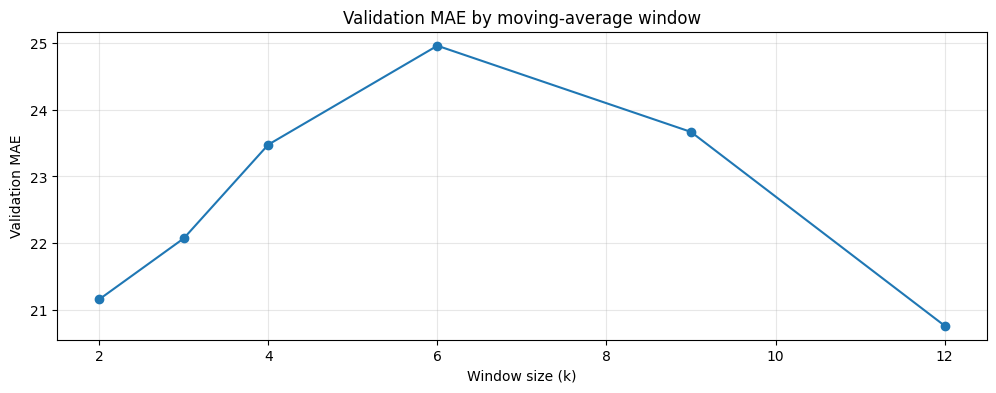

In [17]:
development = ts.iloc[:-12]
validation = development.iloc[-12:]
fit_history = development.iloc[:-12]

candidate_windows = [2, 3, 4, 6, 9, 12]
rows = []
for k in candidate_windows:
    preds = moving_average_forecast(fit_history.to_list(), k, len(validation))
    rows.append({"Window": k, **forecast_metrics(validation, preds)})

window_results = pd.DataFrame(rows).set_index("Window")
display(window_results.round(2))

fig, ax = plt.subplots()
ax.plot(window_results.index, window_results["MAE"], marker="o")
ax.set(title="Validation MAE by moving-average window",
       xlabel="Window size (k)", ylabel="Validation MAE")
plt.show()

Window selection is data-dependent. A lower validation error does not guarantee future superiority. For more robust estimates, consider rolling-origin evaluation across multiple forecast origins.

## 12. Common mistakes to avoid

1. Calculating the training mean using test observations.
2. Choosing a window without considering the data frequency or business problem.
3. Confusing a smoothed historical line with a valid future forecast.
4. Using centered moving averages as real-time model inputs.
5. Ignoring trend and seasonality.
6. Assuming a larger window is always better.
7. Tuning the window on the final test set.
8. Ignoring missing values and how rolling calculations handle them.

## 13. Practice exercises

1. Given `20, 30, 25, 35, 40`, calculate the Average Method forecast for the next three periods.
2. Given `10, 20, 30, 40, 50, 60`, calculate all available 3-period moving averages and the next-period forecast.
3. What changes when the moving-average window increases from 3 to 12?
4. For values `80, 100, 120` and weights `0.2, 0.3, 0.5`, calculate the WMA.
5. If you use the past 28 daily observations to forecast the next 7 days, identify the lookback and horizon.

### Suggested answers

1. Mean = (20 + 30 + 25 + 35 + 40) / 5 = 30. Forecasts: 30, 30, 30.
2. 20, 30, 40, 50. Next forecast = (40 + 50 + 60) / 3 = 50.
3. A larger window generally smooths more but responds more slowly to recent changes.
4. WMA = (0.2 × 80) + (0.3 × 100) + (0.5 × 120) = 106.
5. Lookback = 28 days; horizon = 7 days.

## 14. Key takeaways

**Average Method**
- Uses all training observations.
- Produces a constant forecast.
- Useful as a basic benchmark for stable-level series.

**Moving Average**
- Uses the latest \(k\) observations.
- The window moves forward as new observations arrive.
- Smooths short-term fluctuations.
- Small windows react faster; large windows smooth more but react slower.
- Recursive multi-step forecasts may use earlier predictions.

**Final thought:** Start with a baseline, understand its assumptions, and measure whether a more advanced model genuinely improves forecasting accuracy.

## References
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*: https://otexts.com/fpp3/
- pandas rolling window operations: https://pandas.pydata.org/docs/reference/api/pandas.Series.rolling.html
- pandas time series guide: https://pandas.pydata.org/docs/user_guide/timeseries.html
- scikit-learn model evaluation: https://scikit-learn.org/stable/modules/model_evaluation.html

All examples are synthetic and educational. Choose aggregation, window sizes, missing-data treatment, and metrics based on the real business context.